# Gate lease costs and departure-side allocation

**Question 5 — REAME.md:** How did gate costs change between lease years, and what should NorthByte expect to pay in 2026–2027?

**Exact Case Package question:** “How did NorthByte's gate lease costs change from the 2024-2025 lease year to the 2025-2026 lease year? Based on these trends, what would you expect NorthByte to pay for its gates in 2026-2027?”

## Executive summary
The same 34 gates cost **CAD 9,664,400 in 2024–2025** and **CAD 9,877,700 in 2025–2026**, an increase of **CAD 213,300 (+2.21%)**. Repeating each gate's observed percentage increase gives a **2026–2027 planning estimate of CAD 10.096 million**. Two gates have no assigned routes; their latest recorded leases total **CAD 433,500 (4.39%)**. These are candidates for operational review, not proven immediately recoverable savings.

## Context and method
The audience is NorthByte's finance and network leadership. This notebook answers Q5 and adds a bounded review of gate usage and cost allocation; it does not reclassify flight operating contribution as after-gate profit.

### Sources and key assumptions
- Source files: `data/processed/gate_leases.csv` (one gate–lease-year), `gates.csv` (route assignment rows), `costs.csv` (four expense categories per departure). Raw `data/raw/csv/gates.csv` independently checks lease totals. Definitions: *FirstByte 2026 Data Dictionary*, pp. 2–3; *Case Package*, Airports & Gates Continued and Q5; `REAME.md` is preserved.
- The dictionary defines **2024–2025 as calendar 2024**, **2025–2026 as calendar 2025**, and the missing **2026–2027 as calendar 2026**. Lease ends are exclusive. These are not September–August fiscal years.
- Actual lease sums use integer CAD cents and one record per airport, gate, and lease year. Gate prices repeated on route assignment rows must not be summed.
- Primary forecast: same gates, same assignments, and each gate repeats its one observed percentage escalation. Flat, repeat-dollar, and aggregate-percentage scenarios test this assumption. There is only one year-on-year comparison; scenario bounds are **not a confidence interval**. Contracts, renegotiated prices, capacity, and gate availability are unknown.
- The Case Package explicitly assumes **each airport's total gate cost is split evenly across all NorthByte flights departing from that airport**. We implement this at route level using departure-flight counts. Route-mapped gates identify the assigned lease pool; empty-route gates remain a separate overhead component. Both components are attributed once to departures, then added. No arrival gate charge is added.
- A flight is a distinct `(route_id, cost_date)` with exactly one row for each of Fuel, Crew, Maintenance, Food. Ticket transactions are not flight counts. No revenue data are used; ambiguous purchase dates do not affect this notebook.
- Fiscal-year lease estimates use uniform monthly accrual: FY2024–25 = 4/12 calendar-2024 + 8/12 calendar-2025; FY2025–26 = 4/12 calendar-2025 + 8/12 forecast calendar-2026. They are **allocation estimates, not audited gate expenses**. Rounding to cents uses half-up and deterministic largest-remainder allocation.

In [1]:
from pathlib import Path
import sys
from decimal import Decimal, ROUND_HALF_UP
from fractions import Fraction
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / 'data/processed').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.analysis_common import load_data, setup_style, save_table, save_figure, FY_ORDER

setup_style()

leases = load_data('gate_leases')
gates = load_data('gates')
costs = load_data('costs')

BLUE, GOLD, GREY = '#275D86', '#C38A28', '#747B83'
checks = []

def check(name, condition, detail):
    assert bool(condition), f'{name}: {detail}'

    checks.append({'check': name, 'passed': True, 'detail': str(detail)})

def cents_round(value):
    return int(Decimal(value).quantize(Decimal('1'), rounding=ROUND_HALF_UP))

def money(value): return f'CAD {value:,.2f}'

def show_table(df):
    display(df.style.format({c: '{:,.2f}' for c in df.select_dtypes('floating').columns}).hide(axis='index'))

## Validate the lease grain and flight denominator
Confirm a complete matching portfolio, reconcile the deduplicated raw source independently, and verify the event grain before using flight counts. The route map must cover every observed route exactly once in each lease year and match its departure airport.

In [2]:
keys = ['departure_airport', 'gate_number', 'year']

check('Unique gate-year key', not leases.duplicated(keys).any(), f'{len(leases)} gate-year records')
check('Positive lease costs', leases.annual_gate_cost_cents.gt(0).all(), 'All leases positive')

raw = pd.read_csv(ROOT / 'data/raw/csv/gates.csv', dtype=str, keep_default_na=False)
raw = raw.loc[raw['Year'].isin(['2024-2025', '2025-2026'])].copy()
raw['cost_cents'] = raw.Annual_Gate_Cost.map(lambda s: cents_round(Decimal(s.replace('$','').replace(',','')) * 100))
raw_costs = raw.drop_duplicates(['City', 'Gate_Number', 'Year']).groupby('Year').cost_cents.sum().sort_index()
actual_totals = leases.groupby('year').annual_gate_cost_cents.sum().sort_index()

check('Independent raw lease totals', raw_costs.to_dict() == actual_totals.to_dict(), raw_costs.to_dict())

lease_assignments = gates[gates.route_id.ne('')].copy()

check('Unique route assignment per year', not lease_assignments.duplicated(['year','route_id']).any(), f'{len(lease_assignments)} nonblank route-year mappings')
check('Departure-only gate mapping', lease_assignments.route_id.str[:3].eq(lease_assignments.departure_airport).all(), 'Route origin matches gate airport')

flight_groups = costs.groupby(['route_id','cost_date'])
flight_quality = flight_groups.agg(rows=('cost_id','size'), categories=('cost_type','nunique'))

check('Four rows per flight', flight_quality.rows.eq(4).all(), f'{len(flight_quality):,} departures')
check('Four unique expense categories', flight_quality.categories.eq(4).all() and set(costs.cost_type)=={'Fuel','Crew','Maintenance','Food'}, 'Fuel/Crew/Maintenance/Food')

flights = costs.drop_duplicates(['route_id','cost_date']).loc[lambda d: d.in_scope].copy()

check('All costs in fiscal scope', costs.in_scope.all(), f'{len(costs):,} expense records')
check('All observed routes mapped', all(set(flights.route_id)==set(part.route_id) for _,part in lease_assignments.groupby('year')), '54 routes covered in each lease year')

print(f'Validated {len(leases)} lease records and {len(flights):,} distinct departures; no arrival-side charge.')

Validated 68 lease records and 28,801 distinct departures; no arrival-side charge.


## Actual lease-year changes
Compare the same gates across calendar 2024 and 2025. An unchanged portfolio means the total increase is a price change for this portfolio, rather than additional leased gates. The naive assignment-row sum is shown only as a double-counting diagnostic.

In [3]:
gate_change = leases.pivot(index=['departure_airport','gate_number'], columns='year', values='annual_gate_cost_cents').reset_index()
gate_change = gate_change.rename(columns={'2024-2025':'cost_2024_cents','2025-2026':'cost_2025_cents'})

check('Same 34 gates in both years', len(gate_change)==34 and gate_change[['cost_2024_cents','cost_2025_cents']].notna().all().all(), '34 matching gates')

gate_change['change_cents'] = gate_change.cost_2025_cents - gate_change.cost_2024_cents
gate_change['change_pct'] = gate_change.change_cents / gate_change.cost_2024_cents * 100
gate_change['forecast_2026_cents'] = [cents_round(Decimal(int(b))*Decimal(int(b))/Decimal(int(a))) for a,b in zip(gate_change.cost_2024_cents, gate_change.cost_2025_cents)]
gate_change = gate_change.merge(leases[leases.year.eq('2025-2026')][['departure_airport','gate_number','assigned_route_count']], validate='one_to_one')

for name in ['cost_2024','cost_2025','change','forecast_2026']:
    gate_change[name+'_cad'] = gate_change[name+'_cents']/100

save_table(gate_change, '05_gate_change_forecast')

summary = leases.groupby('year').agg(gates=('gate_number','size'), actual_cents=('annual_gate_cost_cents','sum')).reset_index()
summary['calendar_year'] = [2024,2025]
summary['actual_cad'] = summary.actual_cents/100

naive = gates.groupby('year').annual_gate_cost_cents.sum()
summary['naive_assignment_row_sum_cad'] = summary.year.map(naive)/100
summary['naive_overstatement_cad'] = summary.naive_assignment_row_sum_cad-summary.actual_cad
summary['change_cad'] = summary.actual_cad.diff()
summary['change_pct'] = summary.actual_cad.pct_change()*100

save_table(summary,'05_lease_year_totals')
show_table(summary[['year','calendar_year','gates','actual_cad','change_cad','change_pct','naive_overstatement_cad']])

year,calendar_year,gates,actual_cad,change_cad,change_pct,naive_overstatement_cad
2024-2025,2024,34,"9,664,400.00",nan,nan,"7,758,900.00"
2025-2026,2025,34,"9,877,700.00","213,300.00",2.21,"7,941,900.00"


The latest actual lease total is **CAD 9,877,700**, up **CAD 213,300 (+2.21%)** on the same 34 gates. Summing route assignment rows would instead report CAD 17,819,600, overstating the actual latest total by CAD 7,941,900. Every gate's price increased, but the observed percentage changes differ across gates.

## Forecast the missing calendar-2026 lease year
Repeat-dollar forecasts add each gate's observed CAD increase. The primary forecast repeats each gate's percentage increase: `2026 = 2025² / 2024`, rounded per gate. A separate aggregate percentage scenario repeats the portfolio-wide 2.21% increase. These extrapolations assume no change to the 34-gate portfolio; the flat case is a low-escalation scenario, not a guaranteed floor. No probability is assigned to scenarios.

scenario,forecast_2026_cad,change_from_2025_cad,change_from_2025_pct
Flat lease rates,"9,877,700.00",0.00,0.00
Repeat gate dollar increases,"10,091,000.00","213,300.00",2.16
Repeat portfolio percentage,"10,095,707.68","218,007.68",2.21
Repeat gate percentages (primary),"10,095,844.04","218,144.04",2.21


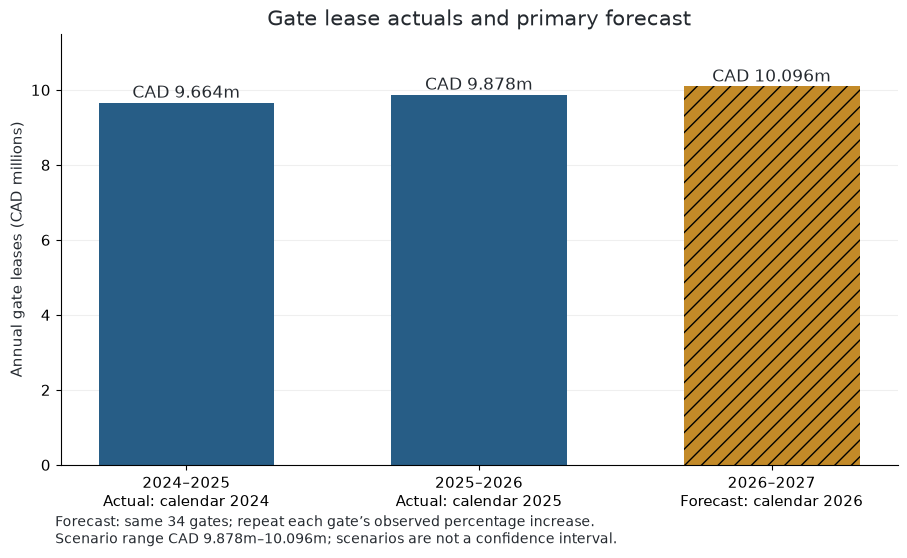

In [4]:
total_2024 = int(gate_change.cost_2024_cents.sum())
total_2025 = int(gate_change.cost_2025_cents.sum())
forecast_total = int(gate_change.forecast_2026_cents.sum())

forecast_scenarios = pd.DataFrame([
    {'scenario':'Flat lease rates','forecast_2026_cents':total_2025,'assumption':'Same gates; calendar-2025 prices unchanged'},
    {'scenario':'Repeat gate dollar increases','forecast_2026_cents':int((2*gate_change.cost_2025_cents-gate_change.cost_2024_cents).sum()),'assumption':'Same gates; each repeats its observed CAD increase'},
    {'scenario':'Repeat portfolio percentage','forecast_2026_cents':cents_round(Decimal(total_2025)**2/Decimal(total_2024)),'assumption':'Same gates; repeats total portfolio percentage increase'},
    {'scenario':'Repeat gate percentages (primary)','forecast_2026_cents':forecast_total,'assumption':'Same gates; each repeats its observed percentage increase'},
])

forecast_scenarios['forecast_2026_cad'] = forecast_scenarios.forecast_2026_cents/100
forecast_scenarios['change_from_2025_cad'] = (forecast_scenarios.forecast_2026_cents-total_2025)/100
forecast_scenarios['change_from_2025_pct'] = (forecast_scenarios.forecast_2026_cents/total_2025-1)*100

save_table(forecast_scenarios, '05_forecast_scenarios')
show_table(forecast_scenarios[['scenario','forecast_2026_cad','change_from_2025_cad','change_from_2025_pct']])

fig, ax = plt.subplots(figsize=(10.8,5.6))
values = [total_2024/1e8,total_2025/1e8,forecast_total/1e8]
bars = ax.bar(['2024–2025\nActual: calendar 2024','2025–2026\nActual: calendar 2025','2026–2027\nForecast: calendar 2026'], values, color=[BLUE,BLUE,GOLD], width=.6)
bars[-1].set_hatch('//')
for bar,value in zip(bars,values): ax.text(bar.get_x()+bar.get_width()/2,value+.13,f'CAD {value:.3f}m',ha='center',fontsize=12)

ax.set_ylim(0,11.5);ax.set_ylabel('Annual gate leases (CAD millions)');ax.set_title('Gate lease actuals and primary forecast')
ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
fig.text(.12,-.03,'Forecast: same 34 gates; repeat each gate’s observed percentage increase.\nScenario range CAD 9.878m–10.096m; scenarios are not a confidence interval.',fontsize=10)

save_figure(fig,'05_lease_cost_forecast');plt.show()

In [5]:
display(Markdown(f"The primary calendar-2026 estimate is **{money(forecast_total/100)}**, an increase of **{money((forecast_total-total_2025)/100)} ({(forecast_total/total_2025-1)*100:.2f}%)** over calendar 2025. The repeat-dollar scenario gives **{money(forecast_scenarios.iloc[1].forecast_2026_cad)}**; the aggregate-percentage scenario gives **{money(forecast_scenarios.iloc[2].forecast_2026_cad)}**. The small difference between percentage methods reflects gate-specific escalation rates. These calculations support a planning budget around **CAD 10.10 million**, pending reconstruction of the missing contracts."))

The primary calendar-2026 estimate is **CAD 10,095,844.04**, an increase of **CAD 218,144.04 (2.21%)** over calendar 2025. The repeat-dollar scenario gives **CAD 10,091,000.00**; the aggregate-percentage scenario gives **CAD 10,095,707.68**. The small difference between percentage methods reflects gate-specific escalation rates. These calculations support a planning budget around **CAD 10.10 million**, pending reconstruction of the missing contracts.

## Locate the lease increase by airport
Airport totals retain each gate once. Compare absolute increases to identify where contract review has the largest budget relevance; a high bill or increase does not by itself establish avoidable spending.

departure_airport,gates,cost_2025_cad,change_cad,change_pct
YYZ,4,"1,899,000.00","47,100.00",2.54
YVR,4,"1,826,100.00","43,800.00",2.46
YUL,3,"1,152,200.00","28,000.00",2.49
YYC,3,"1,090,600.00","24,800.00",2.33
YHZ,3,"714,800.00","14,600.00",2.09
YEG,2,"500,800.00","10,100.00",2.06
YOW,2,"439,100.00","7,800.00",1.81
YWG,1,"217,300.00","4,500.00",2.11


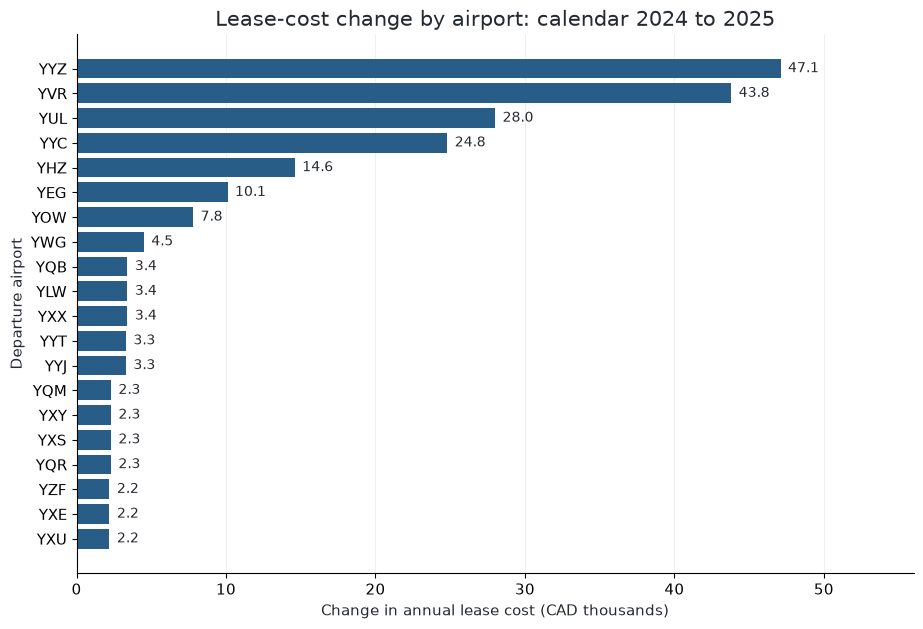

In [6]:
airport_change = gate_change.groupby('departure_airport').agg(cost_2024_cents=('cost_2024_cents','sum'),cost_2025_cents=('cost_2025_cents','sum'),change_cents=('change_cents','sum'),forecast_2026_cents=('forecast_2026_cents','sum'),gates=('gate_number','size')).reset_index()
airport_change['change_pct'] = airport_change.change_cents/airport_change.cost_2024_cents*100
for name in ['cost_2024','cost_2025','change','forecast_2026']: airport_change[name+'_cad']=airport_change[name+'_cents']/100
airport_change['share_of_total_increase_pct'] = airport_change.change_cents/(total_2025-total_2024)*100

save_table(airport_change.sort_values('change_cents',ascending=False),'05_airport_change_forecast')
show_table(airport_change.sort_values('change_cents',ascending=False)[['departure_airport','gates','cost_2025_cad','change_cad','change_pct']].head(8))

plot_data=airport_change.sort_values('change_cents')

fig,ax=plt.subplots(figsize=(10.8,7))
ax.barh(plot_data.departure_airport,plot_data.change_cad/1000,color=BLUE)
ax.set_xlabel('Change in annual lease cost (CAD thousands)');ax.set_ylabel('Departure airport');ax.set_title('Lease-cost change by airport: calendar 2024 to 2025')
ax.set_xlim(0,56);ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
for i,v in enumerate(plot_data.change_cad):ax.text(v/1000+.5,i,f'{v/1000:,.1f}',va='center',fontsize=10)

save_figure(fig,'05_airport_cost_change');plt.show()

In [7]:
hub_ids=['YYZ','YVR','YUL','YYC']
hub_change=int(airport_change[airport_change.departure_airport.isin(hub_ids)].change_cents.sum())

display(Markdown(f"Toronto (YYZ), Vancouver (YVR), Montreal (YUL), and Calgary (YYC) account for **{money(hub_change/100)} ({hub_change/(total_2025-total_2024)*100:.2f}%)** of the total increase. Toronto adds **CAD 47,100**, Vancouver **CAD 43,800**, Montreal **CAD 28,000**, and Calgary **CAD 24,800**. Focus lease negotiations where the absolute budget exposure is largest, while separately testing operational constraints."))

Toronto (YYZ), Vancouver (YVR), Montreal (YUL), and Calgary (YYC) account for **CAD 143,700.00 (67.37%)** of the total increase. Toronto adds **CAD 47,100**, Vancouver **CAD 43,800**, Montreal **CAD 28,000**, and Calgary **CAD 24,800**. Focus lease negotiations where the absolute budget exposure is largest, while separately testing operational constraints.

## Identify unassigned-gate overhead
Blank route assignments identify two unassigned gates in each year. This is stronger evidence of potentially avoidable overhead than merely low flight counts, but the data do not establish that these gates were physically unused, substitutable, or cancellable. Do not interpret a count of assigned routes as gate capacity or utilization percentage.

In [8]:
unused = leases[leases.assigned_route_count.eq(0)].copy()
unused['share_of_year_cost_pct'] = unused.annual_gate_cost_cents/unused.year.map(actual_totals)*100

save_table(unused,'05_unassigned_gate_leases')
show_table(unused[['year','departure_airport','gate_number','annual_gate_cost','share_of_year_cost_pct']])

unused_2024=int(unused[unused.year.eq('2024-2025')].annual_gate_cost_cents.sum())
unused_2025=int(unused[unused.year.eq('2025-2026')].annual_gate_cost_cents.sum())
unused_forecast=int(gate_change[gate_change.assigned_route_count.eq(0)].forecast_2026_cents.sum())

display(Markdown(f"Unassigned gates are **Halifax A3** and **Ottawa A2**. Their combined cost rises from **{money(unused_2024/100)}** to **{money(unused_2025/100)}**, up **{money((unused_2025-unused_2024)/100)} (+{(unused_2025/unused_2024-1)*100:.2f}%)**. The latest total is **{unused_2025/total_2025*100:.2f}%** of the lease bill; the primary forecast carries **{money(unused_forecast/100)}** of annual unassigned-gate overhead into calendar 2026. Verify schedule peaks, contingency needs, accessibility, and contract terms before pursuing release or sharing."))

year,departure_airport,gate_number,annual_gate_cost,share_of_year_cost_pct
2024-2025,YHZ,A3,"220,700.00",2.28
2025-2026,YHZ,A3,"225,200.00",2.28
2024-2025,YOW,A2,"205,000.00",2.12
2025-2026,YOW,A2,"208,300.00",2.11


Unassigned gates are **Halifax A3** and **Ottawa A2**. Their combined cost rises from **CAD 425,700.00** to **CAD 433,500.00**, up **CAD 7,800.00 (+1.83%)**. The latest total is **4.39%** of the lease bill; the primary forecast carries **CAD 441,444.87** of annual unassigned-gate overhead into calendar 2026. Verify schedule peaks, contingency needs, accessibility, and contract terms before pursuing release or sharing.

## Estimate fiscal-year costs and allocate once to departures
For each gate, accrue 4/12 of the earlier calendar-year rate and 8/12 of the later rate. Round the network total half-up to cents and distribute residual cents to gates by largest fractional remainder (stable airport/gate order). Aggregate to airports, retaining separate pools for route-assigned gates and unassigned gates. Allocate each pool across airport departing routes in proportion to distinct flight counts; each departure therefore bears the same airport-wide lease cost, as required by the Case Package. Largest-remainder rounding preserves every cent in each pool. An equal-route allocation would overcharge infrequent routes relative to the required flight rule, so it is not used.

This is an accounting attribution of fixed overhead. Route cancellation does not automatically remove allocated lease costs; doing so can reassign them to remaining departures. The estimated FY2025–26 bill contains eight months of forecast rates. Flight volume comparisons use complete Sep–Aug fiscal years, not partial calendar years.

In [9]:
gate_fy_rows=[]
for row in gate_change.itertuples(index=False):
    for fy,early,late in [(FY_ORDER[0],row.cost_2024_cents,row.cost_2025_cents),(FY_ORDER[1],row.cost_2025_cents,row.forecast_2026_cents)]:
        numerator=int(early)+2*int(late)
        estimate=numerator//3
        gate_fy_rows.append({'fiscal_year':fy,'departure_airport':row.departure_airport,'gate_number':row.gate_number,'assigned_route_count':row.assigned_route_count,'estimated_lease_cents':estimate,'accrual_numerator_cents':numerator,'estimated_lease_cad':estimate/100,'unassigned_gate':row.assigned_route_count==0,'forecast_rate_months':8 if fy==FY_ORDER[1] else 0})

gate_fy=pd.DataFrame(gate_fy_rows)

# Preserve the rounded network monthly-accrual total; allocate residual cents to largest remainders.
for fy,part in gate_fy.groupby('fiscal_year'):
    target=cents_round(Decimal(int(part.accrual_numerator_cents.sum()))/3)
    residual=target-int(part.estimated_lease_cents.sum())
    rank=sorted(part.index,key=lambda i:(-(int(gate_fy.at[i,'accrual_numerator_cents'])%3),i))
    gate_fy.loc[rank[:residual],'estimated_lease_cents']+=1

    check('Fiscal monthly accrual network reconciliation '+fy, int(gate_fy.loc[part.index,'estimated_lease_cents'].sum())==target, f'{target} cents')

gate_fy['estimated_lease_cad']=gate_fy.estimated_lease_cents/100

save_table(gate_fy,'05_fiscal_gate_accrual_estimates')

airport_fy=gate_fy.groupby(['fiscal_year','departure_airport']).agg(estimated_lease_cents=('estimated_lease_cents','sum'),gates=('gate_number','size'),unassigned_gates=('unassigned_gate','sum')).reset_index()
unused_fy=gate_fy[gate_fy.unassigned_gate].groupby(['fiscal_year','departure_airport']).estimated_lease_cents.sum()
airport_fy['unassigned_overhead_cents']=[int(unused_fy.get((r.fiscal_year,r.departure_airport),0)) for r in airport_fy.itertuples()]
airport_fy['route_assigned_pool_cents']=airport_fy.estimated_lease_cents-airport_fy.unassigned_overhead_cents

flight_counts=flights.groupby(['fiscal_year','departure_airport','route_id']).size().rename('departure_flights').reset_index()
airport_counts=flight_counts.groupby(['fiscal_year','departure_airport']).departure_flights.sum().rename('departure_flights').reset_index()
airport_fy=airport_fy.merge(airport_counts,validate='one_to_one')

check('All 20 airports in each fiscal year', len(airport_fy)==40 and airport_fy.departure_flights.gt(0).all(), '40 airport-year observations')

airport_fy['flights_per_leased_gate']=airport_fy.departure_flights/airport_fy.gates
airport_fy['estimated_lease_per_departure_cad']=airport_fy.estimated_lease_cents/100/airport_fy.departure_flights
for name in ['estimated_lease','unassigned_overhead','route_assigned_pool']:airport_fy[name+'_cad']=airport_fy[name+'_cents']/100

save_table(airport_fy,'05_airport_fiscal_usage_allocation')

def allocate_exact(total,weights):
    weights=[int(w) for w in weights]; denominator=sum(weights)
    amounts=[total*w//denominator for w in weights]
    residual=total-sum(amounts)
    rank=sorted(range(len(weights)),key=lambda i:(-(total*weights[i]%denominator),i))
    for i in rank[:residual]:amounts[i]+=1

    return amounts

allocated_parts=[]
for row in airport_fy.itertuples(index=False):
    part=flight_counts[(flight_counts.fiscal_year==row.fiscal_year)&(flight_counts.departure_airport==row.departure_airport)].sort_values('route_id').copy()
    part['assigned_gate_allocation_cents']=allocate_exact(int(row.route_assigned_pool_cents),part.departure_flights)
    part['unassigned_overhead_allocation_cents']=allocate_exact(int(row.unassigned_overhead_cents),part.departure_flights)
    part['total_gate_allocation_cents']=part.assigned_gate_allocation_cents+part.unassigned_overhead_allocation_cents
    part['allocation_basis']='Airport total / airport departure flights; split assigned and unassigned pools'
    part['estimate_status']='Monthly accrual estimate; includes 8 months forecast' if row.fiscal_year==FY_ORDER[1] else 'Monthly accrual estimate; observed lease rates'
    allocated_parts.append(part)

route_allocations=pd.concat(allocated_parts,ignore_index=True)

for name in ['assigned_gate_allocation','unassigned_overhead_allocation','total_gate_allocation']:route_allocations[name+'_cad']=route_allocations[name+'_cents']/100

save_table(route_allocations,'05_route_fiscal_gate_allocations')

allocated_totals=route_allocations.groupby(['fiscal_year','departure_airport']).total_gate_allocation_cents.sum()
expected_totals=airport_fy.set_index(['fiscal_year','departure_airport']).estimated_lease_cents

check('Each airport allocation reconciles to cents', allocated_totals.eq(expected_totals).all(), '40 airport-year totals')
check('Assigned plus unassigned equals total', airport_fy.route_assigned_pool_cents.add(airport_fy.unassigned_overhead_cents).eq(airport_fy.estimated_lease_cents).all(), 'Separate pools, charged once')

fy_summary=airport_fy.groupby('fiscal_year').agg(estimated_lease_cents=('estimated_lease_cents','sum'),assigned_pool_cents=('route_assigned_pool_cents','sum'),unassigned_overhead_cents=('unassigned_overhead_cents','sum'),departure_flights=('departure_flights','sum')).reset_index()
fy_summary['estimated_lease_cad']=fy_summary.estimated_lease_cents/100
fy_summary['assigned_pool_cad']=fy_summary.assigned_pool_cents/100
fy_summary['unassigned_overhead_cad']=fy_summary.unassigned_overhead_cents/100
fy_summary['estimated_gate_cost_per_departure_cad']=fy_summary.estimated_lease_cad/fy_summary.departure_flights
fy_summary['estimate_status']=['Accrual estimate: observed rates','Accrual estimate: 8 months forecast']

save_table(fy_summary,'05_fiscal_allocation_summary')
show_table(fy_summary[['fiscal_year','departure_flights','estimated_lease_cad','assigned_pool_cad','unassigned_overhead_cad','estimated_gate_cost_per_departure_cad','estimate_status']])

fiscal_year,departure_flights,estimated_lease_cad,assigned_pool_cad,unassigned_overhead_cad,estimated_gate_cost_per_departure_cad,estimate_status
FY2024-25,13072,"9,806,600.00","9,375,700.00","430,900.00",750.20,Accrual estimate: observed rates
FY2025-26,15729,"10,023,129.36","9,584,332.78","438,796.58",637.24,Accrual estimate: 8 months forecast


## Compare observed departure activity with gate exposure
The chart uses complete fiscal years and actual distinct departure-flight counts. The upper panel shows fixed-overhead exposure at Halifax and Ottawa; the lower panel ranks calendar-2025 lease rates against complete FY2025–26 departures only as a comparable-rate screening metric. This lower-panel ratio deliberately holds the annual lease-rate basis constant at the latest observed rate; it is not the fiscal-year accrual estimate. A high ratio can suggest a review priority, but cannot establish spare capacity, excessive gates, or savings without occupancy and schedule data.

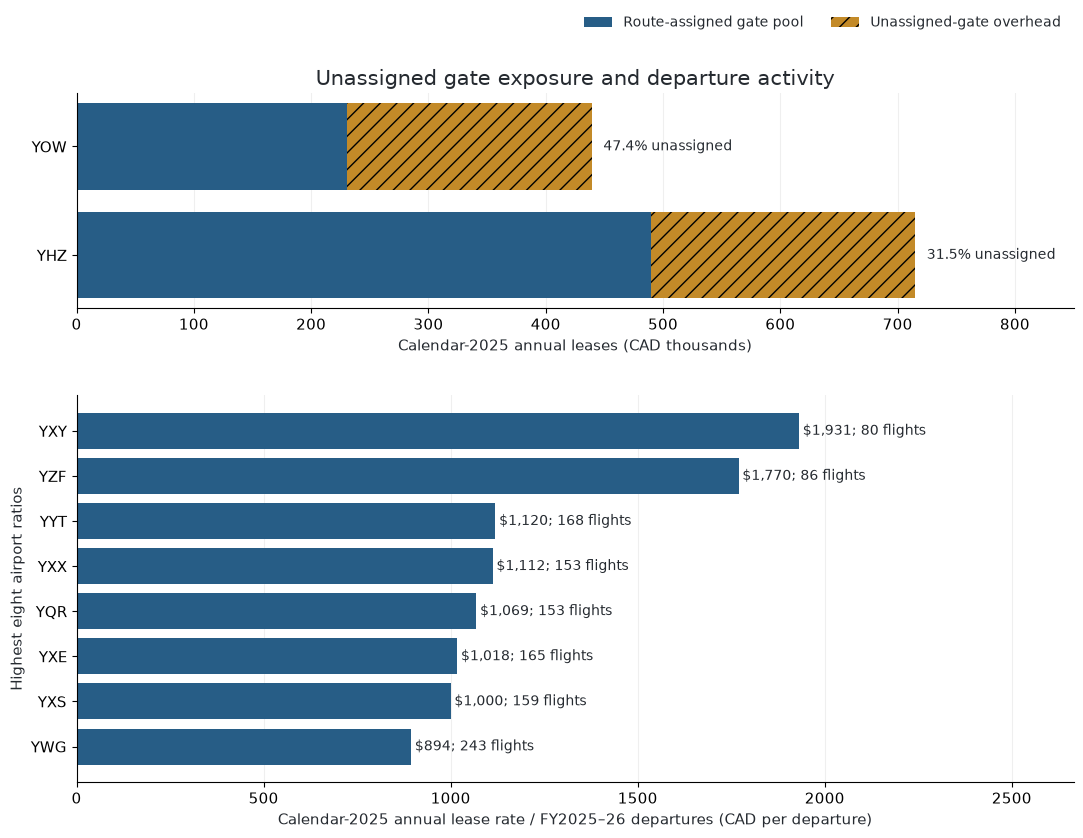

In [10]:
usage_latest=airport_fy[airport_fy.fiscal_year.eq(FY_ORDER[1])].merge(airport_change[['departure_airport','cost_2025_cad']],validate='one_to_one')
usage_latest['latest_recorded_annual_lease_per_fy_departure_cad']=usage_latest.cost_2025_cad/usage_latest.departure_flights

save_table(usage_latest,'05_latest_rate_usage_screen')

fig,axes=plt.subplots(2,1,figsize=(11,8.5),gridspec_kw={'height_ratios':[1,1.8]})

unassigned_airports=leases[leases.year.eq('2025-2026')].copy()
unassigned_airports['unused_cents']=unassigned_airports.annual_gate_cost_cents.where(unassigned_airports.assigned_route_count.eq(0),0)
u=unassigned_airports.groupby('departure_airport').agg(total_cents=('annual_gate_cost_cents','sum'),unused_cents=('unused_cents','sum')).loc[['YHZ','YOW']]

axes[0].barh(u.index,(u.total_cents-u.unused_cents)/1000/100,color=BLUE,label='Route-assigned gate pool')
axes[0].barh(u.index,u.unused_cents/1000/100,left=(u.total_cents-u.unused_cents)/1000/100,color=GOLD,hatch='//',label='Unassigned-gate overhead')
axes[0].set_title('Unassigned gate exposure and departure activity');axes[0].set_xlabel('Calendar-2025 annual leases (CAD thousands)')
axes[0].legend(loc='upper right',bbox_to_anchor=(1.0,1.42),ncol=2,frameon=False,fontsize=10)
axes[0].set_xlim(0,850)
for i,r in enumerate(u.itertuples()):axes[0].text(r.total_cents/100000+10,i,f'{r.unused_cents/r.total_cents*100:.1f}% unassigned',va='center',fontsize=10)

screen=usage_latest.nlargest(8,'latest_recorded_annual_lease_per_fy_departure_cad').sort_values('latest_recorded_annual_lease_per_fy_departure_cad')

axes[1].barh(screen.departure_airport,screen.latest_recorded_annual_lease_per_fy_departure_cad,color=BLUE)
axes[1].set_xlabel('Calendar-2025 annual lease rate / FY2025–26 departures (CAD per departure)')
axes[1].set_ylabel('Highest eight airport ratios');axes[1].set_xlim(0,screen.latest_recorded_annual_lease_per_fy_departure_cad.max()*1.38)
for i,r in enumerate(screen.itertuples()):axes[1].text(r.latest_recorded_annual_lease_per_fy_departure_cad+10,i,f'${r.latest_recorded_annual_lease_per_fy_departure_cad:,.0f}; {r.departure_flights:,} flights',va='center',fontsize=10)

for ax in axes:ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout(h_pad=2.7)

save_figure(fig,'05_departure_usage_overhead');plt.show()

In [11]:
old_fy,new_fy=fy_summary.iloc[0],fy_summary.iloc[1]
flight_growth=(new_fy.departure_flights/old_fy.departure_flights-1)*100
per_flight_change=(new_fy.estimated_gate_cost_per_departure_cad/old_fy.estimated_gate_cost_per_departure_cad-1)*100

display(Markdown(f"Observed departures increased from **{int(old_fy.departure_flights):,}** to **{int(new_fy.departure_flights):,} (+{flight_growth:.2f}%)**. With the monthly accrual and forecast assumptions, estimated gate cost per departure falls from **{money(old_fy.estimated_gate_cost_per_departure_cad)}** to **{money(new_fy.estimated_gate_cost_per_departure_cad)} ({per_flight_change:.2f}%)**. This is fixed-cost dilution over more departures, not proof of adequate gate capacity. Halifax's unassigned gate is **{u.loc['YHZ','unused_cents']/u.loc['YHZ','total_cents']*100:.2f}%** of its latest bill; Ottawa's is **{u.loc['YOW','unused_cents']/u.loc['YOW','total_cents']*100:.2f}%**. Prioritize these two reviews while preserving schedule and contingency requirements."))

Observed departures increased from **13,072** to **15,729 (+20.33%)**. With the monthly accrual and forecast assumptions, estimated gate cost per departure falls from **CAD 750.20** to **CAD 637.24 (-15.06%)**. This is fixed-cost dilution over more departures, not proof of adequate gate capacity. Halifax's unassigned gate is **31.51%** of its latest bill; Ottawa's is **47.44%**. Prioritize these two reviews while preserving schedule and contingency requirements.

## Validation and limits
The checks below reconcile exact cents, raw versus deduplicated totals, departure-flight grain, portfolio completeness, mapping coverage, and allocation pools. They validate the calculations, not the forecast assumptions. Missing calendar-2026 contracts prevent validation of the forecast against actual negotiated lease prices. No gate occupancy, peak departures, aircraft turnaround duration, gate substitutability, termination clauses, or accessibility constraints are available. Neither route counts nor flights per gate reveal capacity utilization. No route revenue, flight contribution, or net-profit number is recomputed here, so these lease allocations must be joined as a separate fixed-overhead layer if later combined with purchase-date revenue and flight-date costs.

In [12]:
validation=pd.DataFrame(checks)

save_table(validation,'05_validation')

print(f'{len(validation)} reconciliation and input checks passed. Forecasts remain scenarios, not observed contract expenses.')

15 reconciliation and input checks passed. Forecasts remain scenarios, not observed contract expenses.


## Answer to Question 5

In [13]:
answer = f"""**Gate costs rose by {money((total_2025-total_2024)/100)} (+{(total_2025/total_2024-1)*100:.2f}%). Budget approximately CAD {forecast_total/1e8:.3f} million for the missing 2026–2027 lease year, subject to recovering the actual contracts.**

### Observed change and next-year expectation

Lease years run January 1 to January 1, end exclusive; they differ from the September–August fiscal years. Each gate is counted once, rather than once per assigned route.

| Lease year | Calendar covered | Annual gate cost (CAD) | Status |
| --- | --- | ---: | --- |
| 2024–2025 | 2024 | {total_2024/100:,.2f} | Recorded |
| 2025–2026 | 2025 | {total_2025/100:,.2f} | Recorded |
| 2026–2027 | 2026 | {forecast_total/100:,.2f} | Forecast: repeat each gate's percentage increase |

The portfolio remains **34 gates across 20 airports**. All gate prices rose; the four hubs account for **{hub_change/(total_2025-total_2024)*100:.2f}%** of the observed increase. Counting unique gates avoids **CAD 7,941,900** of overstatement from the latest route-assignment rows.

The primary forecast rises **{money((forecast_total-total_2025)/100)} (+{(forecast_total/total_2025-1)*100:.2f}%)**. Only one annual change is observed, and missing contracts prevent confirming the 2026–2027 bill.

### Forecast sensitivities

| Assumption for the same gate portfolio | Calendar-2026 cost (CAD) |
| --- | ---: |
| Rates stay flat | {total_2025/100:,.2f} |
| Each gate's dollar increase repeats | {forecast_scenarios.iloc[1].forecast_2026_cad:,.2f} |
| Portfolio-wide percentage increase repeats | {forecast_scenarios.iloc[2].forecast_2026_cad:,.2f} |
| Each gate's percentage increase repeats (primary) | {forecast_total/100:,.2f} |

**CAD 9.878–10.096 million is a scenario span, not a confidence interval or guaranteed contractual range.** Additions, closures and negotiated terms could put actual spending outside it.

### Where should management investigate efficiency?

**Halifax A3 and Ottawa A2 have no assigned routes** in either recorded year. Their calendar-2025 cost is **{money(unused_2025/100)} ({unused_2025/total_2025*100:.2f}% of leases)**, versus **{money(unused_2024/100)}** previously (+{(unused_2025/unused_2024-1)*100:.2f}%). The primary calendar-2026 forecast carries **{money(unused_forecast/100)}** for them.

Review sharing, consolidation and release at renewal after confirming occupancy, contingency and community-service needs. **Unassigned does not prove physically unused; this exposure is not assured savings.** Departures rose **{flight_growth:.2f}%**, but flight counts alone cannot establish gate capacity, congestion or idle time.

### Fiscal allocation: keep estimates separate from recorded leases

Apply the case rule by spreading each airport's gate cost evenly across its departing flights, then aggregating to routes, with no arrival charge. Keep route-assigned and unassigned overhead visible and charge each pool once.

Under uniform monthly accrual:

| Allocation estimate (CAD) | FY2024–25 | FY2025–26 |
| --- | ---: | ---: |
| Gate expense | {old_fy.estimated_lease_cad:,.2f} | {new_fy.estimated_lease_cad:,.2f} |
| Of which: unassigned overhead | {old_fy.unassigned_overhead_cad:,.2f} | {new_fy.unassigned_overhead_cad:,.2f} |
| Gate cost per departure | {old_fy.estimated_gate_cost_per_departure_cad:,.2f} | {new_fy.estimated_gate_cost_per_departure_cad:,.2f} |

Departures increase **{int(old_fy.departure_flights):,} → {int(new_fy.departure_flights):,}**, reducing allocated gate cost per departure by **{-per_flight_change:.2f}%**. FY2025–26 includes **eight months of forecast rates**. Allocations reconcile to airport totals but are not audited expenses or flight operating contribution.

**Priority:** reconstruct missing contracts, plan around **CAD 10.10 million**, and review unassigned gate exposure while protecting required operations."""

display(Markdown(answer))


**Gate costs rose by CAD 213,300.00 (+2.21%). Budget approximately CAD 10.096 million for the missing 2026–2027 lease year, subject to recovering the actual contracts.**

### Observed change and next-year expectation

Lease years run January 1 to January 1, end exclusive; they differ from the September–August fiscal years. Each gate is counted once, rather than once per assigned route.

| Lease year | Calendar covered | Annual gate cost (CAD) | Status |
| --- | --- | ---: | --- |
| 2024–2025 | 2024 | 9,664,400.00 | Recorded |
| 2025–2026 | 2025 | 9,877,700.00 | Recorded |
| 2026–2027 | 2026 | 10,095,844.04 | Forecast: repeat each gate's percentage increase |

The portfolio remains **34 gates across 20 airports**. All gate prices rose; the four hubs account for **67.37%** of the observed increase. Counting unique gates avoids **CAD 7,941,900** of overstatement from the latest route-assignment rows.

The primary forecast rises **CAD 218,144.04 (+2.21%)**. Only one annual change is observed, and missing contracts prevent confirming the 2026–2027 bill.

### Forecast sensitivities

| Assumption for the same gate portfolio | Calendar-2026 cost (CAD) |
| --- | ---: |
| Rates stay flat | 9,877,700.00 |
| Each gate's dollar increase repeats | 10,091,000.00 |
| Portfolio-wide percentage increase repeats | 10,095,707.68 |
| Each gate's percentage increase repeats (primary) | 10,095,844.04 |

**CAD 9.878–10.096 million is a scenario span, not a confidence interval or guaranteed contractual range.** Additions, closures and negotiated terms could put actual spending outside it.

### Where should management investigate efficiency?

**Halifax A3 and Ottawa A2 have no assigned routes** in either recorded year. Their calendar-2025 cost is **CAD 433,500.00 (4.39% of leases)**, versus **CAD 425,700.00** previously (+1.83%). The primary calendar-2026 forecast carries **CAD 441,444.87** for them.

Review sharing, consolidation and release at renewal after confirming occupancy, contingency and community-service needs. **Unassigned does not prove physically unused; this exposure is not assured savings.** Departures rose **20.33%**, but flight counts alone cannot establish gate capacity, congestion or idle time.

### Fiscal allocation: keep estimates separate from recorded leases

Apply the case rule by spreading each airport's gate cost evenly across its departing flights, then aggregating to routes, with no arrival charge. Keep route-assigned and unassigned overhead visible and charge each pool once.

Under uniform monthly accrual:

| Allocation estimate (CAD) | FY2024–25 | FY2025–26 |
| --- | ---: | ---: |
| Gate expense | 9,806,600.00 | 10,023,129.36 |
| Of which: unassigned overhead | 430,900.00 | 438,796.58 |
| Gate cost per departure | 750.20 | 637.24 |

Departures increase **13,072 → 15,729**, reducing allocated gate cost per departure by **15.06%**. FY2025–26 includes **eight months of forecast rates**. Allocations reconcile to airport totals but are not audited expenses or flight operating contribution.

**Priority:** reconstruct missing contracts, plan around **CAD 10.10 million**, and review unassigned gate exposure while protecting required operations.